# ACTIVIDAD 2: REDES NEURONALES CONVOLUCIONALES
## Javier Sin Pelayo
---

En esta actividad, vamos a trabajar con Convolutional Neural Networks para resolver un problema de clasificación de imágenes. En particular, vamos a clasificar diez clases que incluyen fundamentalmente animales y vehículos.

Como las CNN profundas son un tipo de modelo bastante avanzado y computacionalmente costoso, se recomienda hacer la práctica en Google Colaboratory con soporte para GPUs. En [este enlace](https://medium.com/deep-learning-turkey/google-colab-free-gpu-tutorial-e113627b9f5d) se explica cómo activar un entorno con GPUs. *Nota: para leer las imágenes y estandarizarlas al mismo tamaño se usa la librería opencv. Esta ĺibrería está ya instalada en el entorno de Colab, pero si trabajáis de manera local tendréis que instalarla.*

El dataset a utilizar consiste en 60000 imágenes a color de 10 clases de animales y vehículos. El dataset en cuestión se denomina [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) y es más complejo que el dataset MNIST que hemos utilizado en la actividad 1. Aunque tiene las mismas clases (10), los animales y vehículos pueden aparecer en distintas poses, en distintas posiciones de la imagen o con otros animales/ vehículos en pantalla (si bien el elemento a clasificar siempre aparece en la posición predominante).

## Carga de los datos

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix

# Fijamos semillas para que las comparaciones sean reproducibles.
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [5]:
import os
import tarfile
import pickle
import numpy as np
from google.colab import drive

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Definir ruta del archivo comprimido original en tu Drive
drive_path = '/content/drive/My Drive/Colab Notebooks/Data/cifar-10-batches-py-target_archive'
local_extract_path = '/content/cifar_local'

# Función para cargar un lote individual usando pickle
def load_batch(fpath, label_key='labels'):
    with open(fpath, 'rb') as f:
        d = pickle.load(f, encoding='bytes')
        # Decodificar las claves de bytes a strings
        d_decoded = {k.decode('utf8'): v for k, v in d.items()}
    data = d_decoded['data']
    labels = d_decoded[label_key]
    data = data.reshape(len(data), 3, 32, 32).transpose(0, 2, 3, 1)
    return data, np.array(labels)

# 3. Extraer el archivo directamente en la máquina virtual de Colab
if os.path.exists(drive_path):
    if not os.path.exists(local_extract_path):
        print("Extrayendo el archivo local de CIFAR-10 desde Drive...")
        os.makedirs(local_extract_path, exist_ok=True)
        with tarfile.open(drive_path, 'r:gz') as tar:
            tar.extractall(path=local_extract_path)
    else:
        print("El archivo ya está extraído localmente.")

    # Buscar la carpeta extraída dentro del directorio (suele llamarse 'cifar-10-batches-py')
    extracted_folders = [f for f in os.listdir(local_extract_path) if os.path.isdir(os.path.join(local_extract_path, f))]
    if extracted_folders:
        base_dir = os.path.join(local_extract_path, extracted_folders[0])
    else:
        base_dir = local_extract_path

    print(f"Cargando datos usando pickle desde: {base_dir}")

    # Cargar los 5 lotes de entrenamiento de forma secuencial
    x_train_list = []
    y_train_list = []
    for i in range(1, 6):
        batch_path = os.path.join(base_dir, f'data_batch_{i}')
        x_b, y_b = load_batch(batch_path)
        x_train_list.append(x_b)
        y_train_list.append(y_b)

    X = np.concatenate(x_train_list, axis=0)
    Y = np.concatenate(y_train_list, axis=0)

    # Cargar el lote de prueba (test_batch)
    test_path = os.path.join(base_dir, 'test_batch')
    x_test, y_test = load_batch(test_path)
    y_test = y_test.reshape(-1, 1)
    Y = Y.reshape(-1, 1)

    # Separar entrenamiento y validación conservando las proporciones de tu libreta
    (x_train, x_valid) = (X[:40000], X[40000:])
    (y_train, y_valid) = (Y[:40000], Y[40000:])

    print(f"¡Datos cargados con éxito! Entrenamiento: {x_train.shape}, Validación: {x_valid.shape}, Test: {x_test.shape}")
else:
    print(f"ERROR: No se encontró el archivo en Google Drive: {drive_path}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
El archivo ya está extraído localmente.
Cargando datos usando pickle desde: /content/cifar_local/cifar-10-batches-py
¡Datos cargados con éxito! Entrenamiento: (40000, 32, 32, 3), Validación: (10000, 32, 32, 3), Test: (10000, 32, 32, 3)


In [6]:
# Normalizamos como de costumbre
x_train = x_train / 255.
x_valid = x_valid / 255.
x_test = x_test / 255.

In [7]:
# Esta variable contiene un mapeo de número de clase a elemento (animal o vehículo).
MAP_ELEMENTS = {
    0: 'avion', 1: 'coche', 2: 'ave',
    3: 'gato', 4: 'ciervo', 5: 'perro', 6: 'rana',
    7: 'caballo', 8: 'barco', 9: 'camion'
}

In [8]:
# Función auxiliar para convertir las etiquetas a codificación one-hot
def convert_to_one_hot(labels, num_classes):
    return np.squeeze(np.array([to_categorical(label, num_classes=num_classes) for label in labels]))

# Convertimos las etiquetas de entrenamiento, validación y prueba
num_classes = 10
y_train_one_hot = convert_to_one_hot(y_train, num_classes)
y_valid_one_hot = convert_to_one_hot(y_valid, num_classes)
y_test_one_hot = convert_to_one_hot(y_test, num_classes)

# Verificamos las conversiones
print(y_train_one_hot.shape)
print(y_valid_one_hot.shape)
print(y_test_one_hot.shape)

(40000, 10)
(10000, 10)
(10000, 10)


## Ejercicio

Utilizando Convolutional Neural Networks con Keras, entrenar un clasificador que sea capaz de reconocer una imagen de las incluidas en CIFAR-10 con la mayor accuracy posible. Redactar un informe analizando varias de las alternativas probadas y los resultados obtenidos.

A continuación se detallan una serie de aspectos orientativos que podrían ser analizados en vuestro informe (no es necesario tratar todos ellos ni mucho menos, esto son ideas orientativas de aspectos que podéis explorar):

*   Análisis de los datos a utilizar.
*   Análisis de resultados, obtención de métricas de *precision* y *recall* por clase y análisis de qué clases obtienen mejores o peores resultados.
*   Análisis visual de los errores de la red. ¿Qué tipo de imágenes dan más problemas a nuestro modelo?
*   Comparación de modelos CNNs con un modelo de Fully Connected para este problema.
*   Utilización de distintas arquitecturas CNNs, comentando aspectos como su profundidad, hiperparámetros utilizados, optimizador, uso de técnicas de regularización, *batch normalization*, etc.
*   [ *algo más difícil* ] Utilización de *data augmentation*. Esto puede conseguirse con la clase [ImageDataGenerator](https://keras.io/preprocessing/image/#imagedatagenerator-class) de Keras.

Notas:
* Te recomendamos mantener los conjuntos de entrenamiento, test y prueba que se crean en el Notebook. No obstante, si crees que modificando tales conjuntos puedes lograr mejores resultados (o que puedes lograr los mismos resultados con menos datos, lo cual es también un logro), eres libre de hacerlo.
* No es necesario mostrar en el notebook las trazas de entrenamiento de todos los modelos entrenados, si bien una buena idea seria guardar gráficas de esos entrenamientos para el análisis. Sin embargo, **se debe mostrar el entrenamiento completo del mejor modelo obtenido y la evaluación de los datos de test con este modelo**.

### Exploración inicial

Comprobamos el tamaño de los conjuntos y la distribución de clases antes de entrenar. El conjunto de test se reserva para la evaluación final.

Entrenamiento: (40000, 32, 32, 3), validación: (10000, 32, 32, 3), test: (10000, 32, 32, 3)


,clase,entrenamiento,validación
0,avion,3986,1014
1,coche,3986,1014
2,ave,4048,952
3,gato,3984,1016
4,ciervo,4003,997
5,perro,3975,1025
6,rana,4020,980
7,caballo,4023,977
8,barco,3997,1003
9,camion,3978,1022


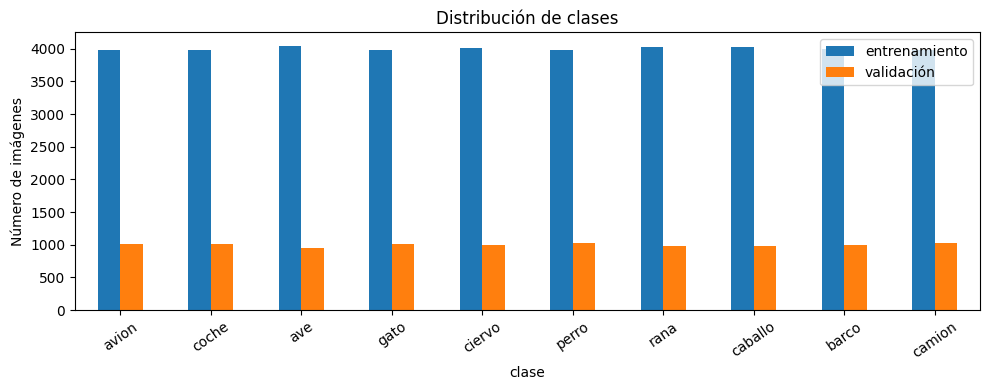

In [9]:
# Distribución de clases en entrenamiento y validación
class_names = [MAP_ELEMENTS[i] for i in range(num_classes)]
train_counts = np.bincount(y_train.reshape(-1), minlength=num_classes)
valid_counts = np.bincount(y_valid.reshape(-1), minlength=num_classes)

print(f"Entrenamiento: {x_train.shape}, validación: {x_valid.shape}, test: {x_test.shape}")
class_distribution = pd.DataFrame({
    "clase": class_names,
    "entrenamiento": train_counts,
    "validación": valid_counts,
})
display(class_distribution)

fig, ax = plt.subplots(figsize=(10, 4))
class_distribution.set_index("clase").plot(kind="bar", ax=ax)
ax.set_ylabel("Número de imágenes")
ax.set_title("Distribución de clases")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()


### Modelos candidatos

Comparamos un baseline *fully connected*, una CNN sencilla y una CNN más profunda con normalización por lotes, *dropout* y aumento de datos. Todos usan la misma partición de entrenamiento/validación; la selección se hace por `val_accuracy`.

In [13]:
def compile_model(model):
    """Compila un clasificador multiclase con el mismo criterio de comparación."""
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
        metrics=["accuracy"],
    )
    return model


def build_fully_connected():
    """Baseline denso: permite comparar el efecto de preservar la estructura espacial."""
    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax"),
    ], name="fully_connected")
    return compile_model(model)


def build_small_cnn():
    """CNN compacta sin aumento de datos, como primer modelo convolucional."""
    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.35),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation="softmax"),
    ], name="cnn_sencilla")
    return compile_model(model)


def build_deep_cnn():
    """CNN profunda con aumento de datos, BatchNorm y regularización."""
    augmentation = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
    ], name="aumento_datos")

    inputs = keras.Input(shape=(32, 32, 3))
    x = augmentation(inputs)
    for filters, dropout_rate in [(64, 0.2), (128, 0.3), (256, 0.4)]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(dropout_rate)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return compile_model(keras.Model(inputs, outputs, name="cnn_profunda"))


model_builders = {
    "Fully connected": build_fully_connected,
    "CNN sencilla": build_small_cnn,
    "CNN profunda + augmentation": build_deep_cnn,
}

### Entrenamiento y selección del mejor modelo

Se entrena cada alternativa con *early stopping* y reducción adaptativa del *learning rate*. El mejor checkpoint se determina únicamente con validación.

In [14]:
from pathlib import Path

CHECKPOINT_DIR = Path("checkpoints_cifar10")
CHECKPOINT_DIR.mkdir(exist_ok=True)
EPOCHS = 30
BATCH_SIZE = 128
histories = {}
validation_scores = {}

for model_name, build_model in model_builders.items():
    print(f"\nEntrenando: {model_name}")
    model = build_model()
    checkpoint_path = CHECKPOINT_DIR / f"{model.name}.keras"
    callbacks = [
        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path), monitor="val_accuracy",
            mode="max", save_best_only=True, verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=3,
            min_lr=1e-6, verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy", mode="max", patience=7,
            restore_best_weights=True, verbose=1,
        ),
    ]
    history = model.fit(
        x_train, y_train_one_hot,
        validation_data=(x_valid, y_valid_one_hot),
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        callbacks=callbacks, verbose=1,
    )
    histories[model_name] = history.history
    validation_scores[model_name] = max(history.history["val_accuracy"])

results = pd.DataFrame.from_dict(
    validation_scores, orient="index", columns=["mejor_accuracy_validación"]
).sort_values("mejor_accuracy_validación", ascending=False)
display(results)

best_model_name = results.index[0]
# Cargamos el checkpoint con mayor val_accuracy para garantizar que se evalúa
# la mejor época y no necesariamente la última.
model_name_to_file = {
    "Fully connected": "fully_connected.keras",
    "CNN sencilla": "cnn_sencilla.keras",
    "CNN profunda + augmentation": "cnn_profunda.keras",
}
best_model = keras.models.load_model(CHECKPOINT_DIR / model_name_to_file[best_model_name])
print(f"Modelo seleccionado: {best_model_name} (val_accuracy={results.iloc[0, 0]:.4f})")


Entrenando: Fully connected
Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1945 - loss: 2.2840
Epoch 1: val_accuracy improved from None to 0.33400, saving model to checkpoints_cifar10/fully_connected.keras

Epoch 1: finished saving model to checkpoints_cifar10/fully_connected.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.2333 - loss: 2.1122 - val_accuracy: 0.3340 - val_loss: 1.9386 - learning_rate: 0.0010
Epoch 2/30
299/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2731 - loss: 1.9971
Epoch 2: val_accuracy improved from 0.33400 to 0.33990, saving model to checkpoints_cifar10/fully_connected.keras

Epoch 2: finished saving model to checkpoints_cifar10/fully_connected.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.2799 - loss: 1.9870 - val_accuracy: 0.3399 - val_loss: 1.9167 - learning_rate: 0.0010
Epoch 3/30
309/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2902 - loss: 1.9643
Epoch 3: val_accuracy improved from 0.33990 to 0.

,mejor_accuracy_validación
CNN profunda + augmentation,0.8587
CNN sencilla,0.8013
Fully connected,0.4352


Modelo seleccionado: CNN profunda + augmentation (val_accuracy=0.8587)


### Evolución del entrenamiento

Mostramos las curvas completas del modelo seleccionado, incluyendo las épocas detenidas por *early stopping*.

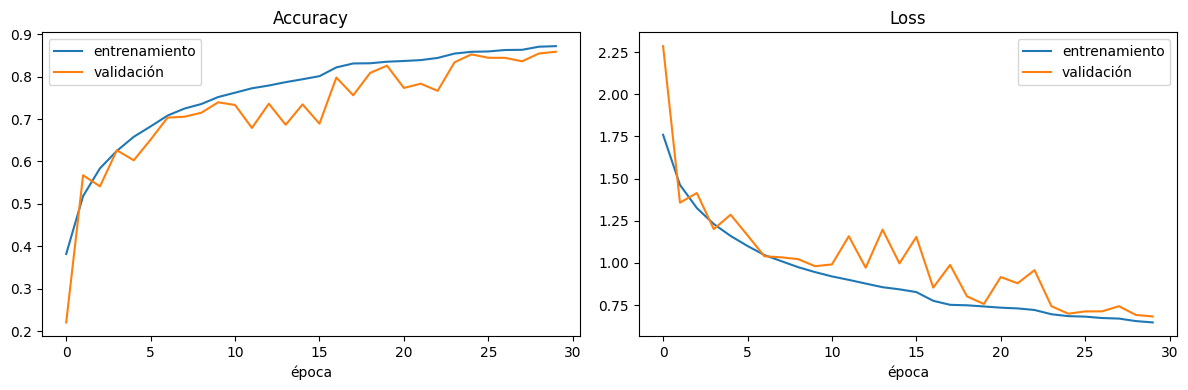

In [15]:
best_history = histories[best_model_name]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_history["accuracy"], label="entrenamiento")
axes[0].plot(best_history["val_accuracy"], label="validación")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("época")
axes[0].legend()
axes[1].plot(best_history["loss"], label="entrenamiento")
axes[1].plot(best_history["val_loss"], label="validación")
axes[1].set_title("Loss")
axes[1].set_xlabel("época")
axes[1].legend()
plt.tight_layout()
plt.show()

### Evaluación final sobre test

El conjunto de test se utiliza una sola vez, después de seleccionar el modelo mediante validación.

In [16]:
test_loss, test_accuracy = best_model.evaluate(x_test, y_test_one_hot, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

y_true = y_test.reshape(-1)
y_pred = np.argmax(best_model.predict(x_test, batch_size=BATCH_SIZE, verbose=1), axis=1)
print(classification_report(
    y_true, y_pred, target_names=class_names, digits=4, zero_division=0
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8482 - loss: 0.6990
Test loss: 0.6990
Test accuracy: 0.8482
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
              precision    recall  f1-score   support

       avion     0.8544    0.8860    0.8699      1000
       coche     0.9025    0.9530    0.9270      1000
         ave     0.8352    0.8010    0.8178      1000
        gato     0.8507    0.5870    0.6947      1000
      ciervo     0.8722    0.8120    0.8410      1000
       perro     0.8337    0.7570    0.7935      1000
        rana     0.7390    0.9570    0.8340      1000
     caballo     0.8745    0.8850    0.8797      1000
       barco     0.9119    0.9110    0.9115      1000
      camion     0.8383    0.9330    0.8831      1000

    accuracy                         0.8482     10000
   macro avg     0.8512    0.8482    0.8452     10000
weighted avg     0.8512    0.8482    0.8452     10000



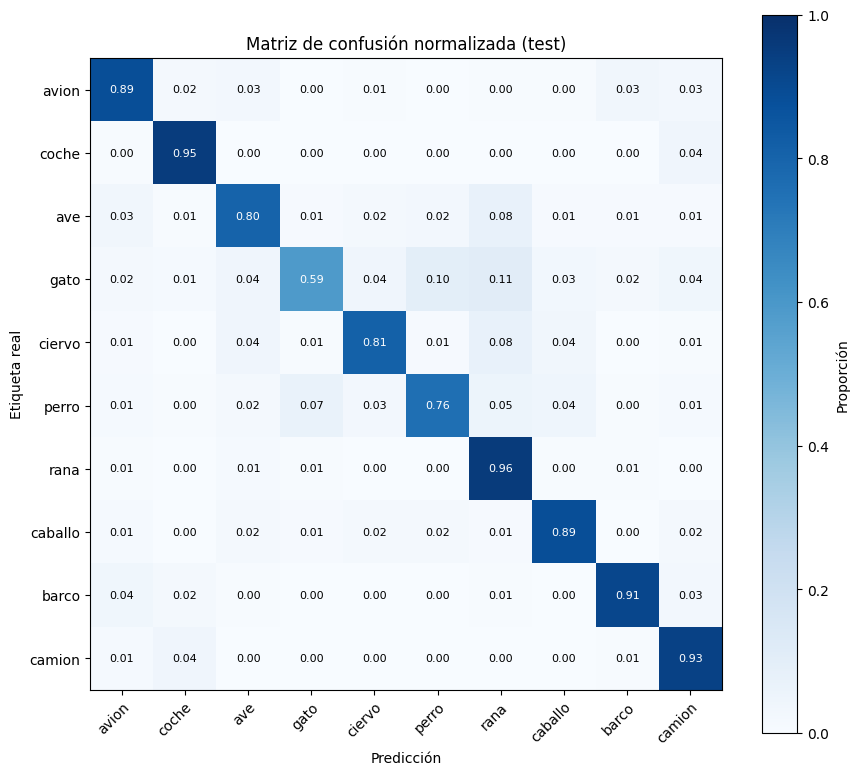

In [17]:
# Matriz de confusión normalizada por clase verdadera
cm = confusion_matrix(y_true, y_pred, normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(num_classes), yticks=range(num_classes),
       xticklabels=class_names, yticklabels=class_names,
       xlabel="Predicción", ylabel="Etiqueta real",
       title="Matriz de confusión normalizada (test)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for row in range(num_classes):
    for col in range(num_classes):
        ax.text(col, row, f"{cm[row, col]:.2f}", ha="center", va="center",
                color="white" if cm[row, col] > 0.55 else "black", fontsize=8)
fig.colorbar(image, ax=ax, label="Proporción")
plt.tight_layout()
plt.show()

### Inspección visual de errores

Las siguientes imágenes permiten observar qué ejemplos confunde el modelo y entre qué clases.

Imágenes mal clasificadas: 1518 de 10000


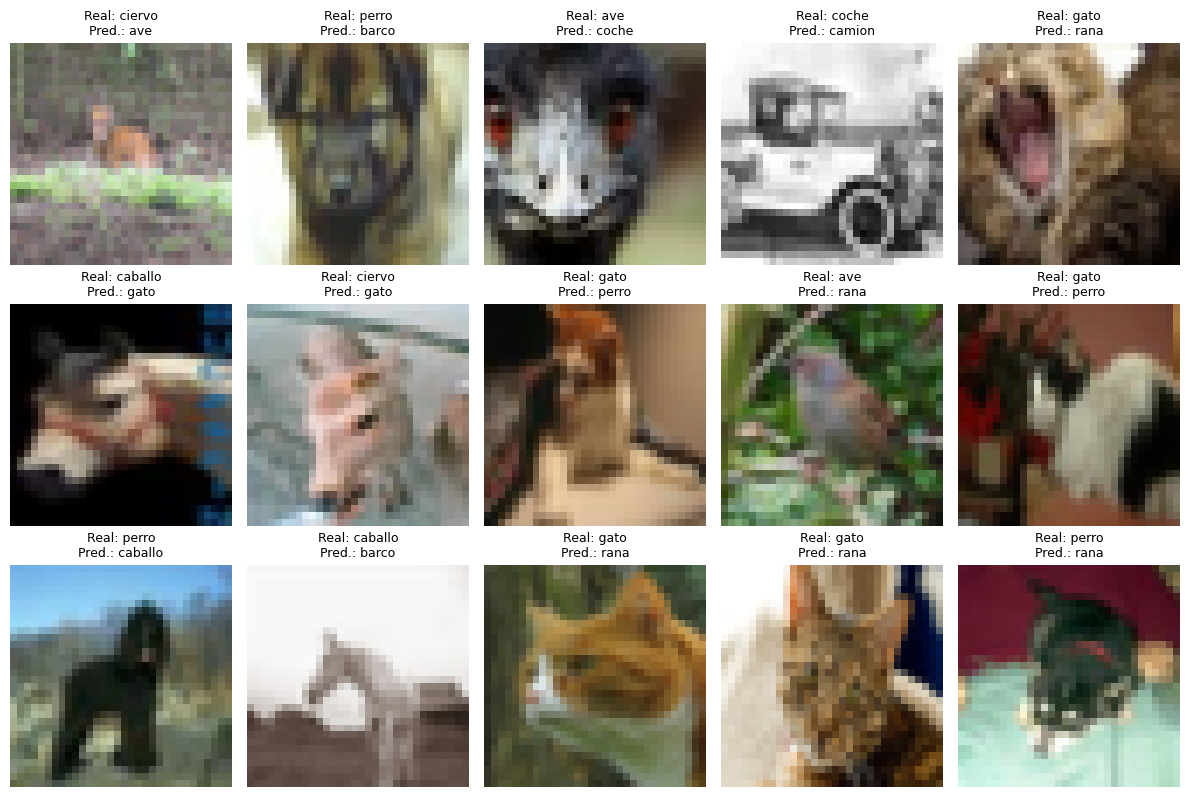

In [18]:
wrong = np.flatnonzero(y_true != y_pred)
print(f"Imágenes mal clasificadas: {len(wrong)} de {len(y_true)}")

if len(wrong):
    shown = wrong[:15]
    cols = 5
    rows = int(np.ceil(len(shown) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 2.7 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, idx in zip(axes, shown):
        ax.imshow(x_test[idx])
        ax.set_title(f"Real: {class_names[y_true[idx]]}\nPred.: {class_names[y_pred[idx]]}", fontsize=9)
        ax.axis("off")
    for ax in axes[len(shown):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Análisis de datos y comparación de modelos

### Datos y preparación

CIFAR-10 contiene 60.000 imágenes RGB de 32×32 píxeles distribuidas en 10 clases equilibradas. En este notebook se usan 40.000 imágenes para entrenar, 10.000 para validación y las 10.000 del conjunto oficial de test para la evaluación final. Las imágenes se escalan a [0, 1] y las etiquetas se convierten a codificación *one-hot*. La partición de validación sirve para comparar modelos y reservar test para la evaluación final.

La resolución reducida hace que algunos objetos ocupen pocos píxeles y que clases visualmente parecidas puedan confundirse. Por eso, junto con la accuracy global, conviene revisar precisión y *recall* por clase, la matriz de confusión y ejemplos de errores.

### Resultados de entrenamiento y validación

La tabla recoge las métricas de la época con mejor val_accuracy para cada candidato, según el nuevo registro de entrenamiento.

| Modelo | Mejor época | Accuracy de entrenamiento | Accuracy de validación | val_loss |
|---|---:|---:|---:|---:|
| Fully connected | 29 | 39,40 % | 43,52 % | 1,7589 |
| CNN sencilla | 30 | 84,45 % | 80,13 % | 0,8238 |
| CNN profunda + *augmentation* | 30 | 87,19 % | **85,87 %** | **0,6820** |

La CNN profunda supera a la sencilla en **5,74 puntos porcentuales** de accuracy de validación, y al modelo denso en **42,35 puntos**. La CNN sencilla también aventaja al modelo denso en 36,61 puntos. La comparación indica que las convoluciones aprovechan mejor la estructura espacial de CIFAR-10 y que la arquitectura profunda con aumento de datos es el mejor candidato de esta ejecución.

En el modelo *fully connected*, la accuracy de validación es mayor que la de entrenamiento. Esto puede ocurrir porque el *dropout* está activo mientras se entrena y desactivado al validar; por sí solo no indica fuga de datos. La CNN sencilla presenta una brecha entrenamiento-validación de 4,32 puntos, frente a 1,32 puntos en la CNN profunda. Esta última brecha, junto con su menor pérdida de validación, es consistente con mejor generalización en esta ejecución.

### Arquitecturas e hiperparámetros

- **Fully connected:** aplana cada imagen y la procesa con capas densas de 512 y 256 neuronas, con *dropout* de 0,4 y 0,3. Su rendimiento bajo muestra la dificultad de clasificar estas imágenes sin aprovechar directamente las relaciones entre píxeles vecinos.
- **CNN sencilla:** usa dos bloques convolucionales de 32 y 64 filtros, *max pooling*, *dropout* y una capa densa de 128 neuronas. Alcanza 80,13% de validación.
- **CNN profunda + augmentation:** usa bloques de 64, 128 y 256 filtros, convoluciones con *batch normalization*, *max pooling* y *dropout*, seguidos de *global average pooling*. Alcanza 85,87% de validación y obtiene la menor pérdida de validación.

Los tres modelos comparten Adam con tasa inicial 0.001, entropía cruzada categórica con *label smoothing* 0.05, lotes de 128 y un máximo de 30 épocas. ReduceLROnPlateau redujo la tasa a 0.0005 para el modelo denso, 0.00025 para la CNN sencilla y 0.000125 para la CNN profunda. Las CNN alcanzaron su mejor accuracy de validación en la última época permitida; podría probarse un entrenamiento más largo, seleccionando los pesos con validación.

La CNN profunda añade *augmentation* (volteo horizontal, pequeños desplazamientos, rotación y zoom) junto con *batch normalization* y *dropout*. Estas técnicas pueden ayudar a reducir el sobreajuste y a generalizar ante variaciones de posición y apariencia. Sin embargo, la CNN profunda también cambia la profundidad, el número de filtros y el *pooling* respecto a la CNN sencilla; por tanto, esta comparación no permite atribuir la mejora a una técnica aislada.

### Evaluación final en test

El modelo seleccionado, la CNN profunda con *augmentation*, obtiene **test loss = 0,6990** y **84,82% de accuracy**: clasifica correctamente 8.482 de las 10.000 imágenes y falla en 1.518 (15,18%). La accuracy de test queda 1,05 puntos por debajo de la accuracy de validación (85,87%), una diferencia moderada en esta ejecución.

| Clase | Precisión | Recall | F1 |
|---|---:|---:|---:|
| avión | 85,44 % | 88,60 % | 86,99 % |
| coche | 90,25 % | 95,30 % | **92,70 %** |
| ave | 83,52 % | 80,10 % | 81,78 % |
| gato | 85,07 % | **58,70 %** | **69,47 %** |
| ciervo | 87,22 % | 81,20 % | 84,10 % |
| perro | 83,37 % | 75,70 % | 79,35 % |
| rana | 73,90 % | 95,70 % | 83,40 % |
| caballo | 87,45 % | 88,50 % | 87,97 % |
| barco | **91,19 %** | 91,10 % | 91,15 % |
| camión | 83,83 % | 93,30 % | 88,31 % |

La precisión macro y ponderada es 85,12%, el recall global es 84,82% y el F1 macro y ponderado es 84,52%. Cada clase tiene 1.000 imágenes de test, por lo que los promedios macro y ponderado coinciden salvo redondeos.

### Matriz de confusión y análisis de errores

La matriz está normalizada por etiqueta verdadera: cada fila muestra cómo se distribuyen las imágenes reales de una clase entre las predicciones y su diagonal corresponde al recall.

- **Gato:** tiene el recall más bajo (58,70%). El 11% de los gatos se predice como rana y el 10% como perro. Aunque la precisión de gato es 85,07%, el modelo deja sin detectar muchos gatos.
- **Perro:** alcanza 75,70% de recall y se confunde principalmente con gato (7%) y rana (5%).
- **Rana:** logra el recall más alto (95,70%), pero su precisión es la más baja (73,90%). La matriz muestra falsos positivos desde gato (11%), ave (8%), ciervo (8%) y perro (5%): el modelo encuentra casi todas las ranas reales, pero también asigna esa etiqueta a imágenes de otras clases.
- **Coche y camión:** hay confusión en ambos sentidos; el 4% de los coches se clasifica como camión y el 4% de los camiones como coche. Coche mantiene un F1 alto de 92,70%, mientras que camión obtiene 93,30% de recall y 83,83% de precisión.
- **Barco y caballo:** mantienen resultados equilibrados, con F1 de 91,15% y 87,97%, respectivamente.

Las 1.518 imágenes mal clasificadas representan el 15,18% del test, coherente con la accuracy de 84,82%. La galería de errores puede ayudar a comprobar si las confusiones se relacionan con objetos pequeños, poses poco habituales, fondos complejos o imágenes ambiguas; la matriz por sí sola no permite atribuir los fallos a esas causas.

### Conclusión

La CNN profunda con *augmentation* fue el mejor de los tres candidatos según validación (85,87%) y obtuvo **84,82% de accuracy y 84,52% de F1 macro en test**. El modelo reconoce especialmente bien coche y barco. Su debilidad principal es gato, cuyo recall de 58,70% indica que omite muchas imágenes de esa clase; rana presenta el patrón opuesto, con recall alto y menor precisión por falsos positivos.

En conjunto, los resultados muestran la ventaja de las CNN sobre el baseline denso y un rendimiento bastante equilibrado para la mayoría de las clases. Como siguiente experimento, conviene analizar los errores entre gato, perro y rana y probar cambios controlados en la arquitectura o en el aumento de datos. Los nuevos ajustes deben seleccionarse con validación, dejando el conjunto de test para la evaluación final.